# JOJA: Analyse exploratoire des données

## Contexte et objectif

Nous disposons des données d'un site de livraison de courses : **~3,4 millions de commandes** passées par **~206 000 clients**, chaque client ayant entre 4 et 100 commandes. Les produits sont regroupés en **rayons** (*aisles*), eux-mêmes regroupés en **départements**.

Objectif : explorer ces données pour en tirer des **insights actionnables**, c'est-à-dire des constats chiffrés qui débouchent sur une décision concrète pouvant améliorer l'activité du e-commerce.

## Les fichiers .csv téléchargés

| Fichier | Une ligne = | Colonnes clés |
|---|---|---|
| `orders` | une commande | `order_id`, `user_id`, `order_number` (rang de la commande du client), `order_dow` (jour, 0 = dimanche), `order_hour_of_day` (heure), `days_since_prior_order` |
| `order_products` | un produit dans une commande | `order_id`, `product_id`, `add_to_cart_order` (position dans le panier), `reordered` (1 = déjà commandé avant) |
| `products` | un produit | `product_id`, `product_name`, `aisle_id`, `department_id` |
| `aisles` | un rayon | `aisle_id`, `aisle` |
| `departments` | un département | `department_id`, `department` |


## Méthodologie

Pour comprendre ces données, nous utilisons la méthode EDA (exploratory data analysis). D'après nos recherches, cette méthode consiste à "transformer un dataset brut en un objet compréhensible. Elle permet de révéler des structures invisibles, d’identifier des biais et d’orienter les choix méthodologiques pour les analyses futures" ([iana-data](https://www.iana-data.org/articles/analyse-exploratoire-des-donnees-eda/#definition)) :

1. **Chargement et typage** (lire les fichiers, choisir des types adaptés au volume)
2. **Contrôle qualité** (dimensions, valeurs manquantes, valeurs aberrantes)
3. **Préparation** (merge/réorganiser les données qui vont ensemble)
4. **Analyse question par question** : problème → mesure → **un** graphique adapté → observation → piste d'action.
5. **Synthèse** 

## Outils et justification des choix

| Paquet | Rôle | Pourquoi ce choix |
|---|---|---|
| **pandas** | manipulation de données tabulaires | structure `DataFrame` ; gère nos volumes (32 M lignes) en mémoire vive |
| **numpy** | calcul numérique vectorisé | opérations sur des tableaux entiers sans boucle Python |
| **matplotlib** | graphiques | bibliothèque de référence pour personnaliser les éléments d'un graphique (axes, titres, légendes) |
| **seaborn** | graphiques statistiques | introduite à partir des questions qui en ont besoin |

## Règle sur les visualisations

Nous n'utilisons pas le même graphique pour des besoins différents :

| Besoin | Graphique retenu |
|---|---|
| **distribution** (répartition d'une variable) | histogramme, boîte à moustaches |
| **comparaison** (classer des catégories) | diagramme en barres |
| **proportion** (part d'un tout) | barres empilées à 100 % |
| **relation** (lien entre deux variables) | nuage de points, carte de chaleur |


# 1. Préparation des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path("datasets")

pd.set_option("display.max_columns", None)   
sns.set_theme(style="whitegrid")           

print("pandas", pd.__version__)

pandas 3.0.5


## 1.1 Chargement et typage

`order_products.csv` fait **32 millions de lignes**. Si on laisse pandas deviner les types, il met des `int64`
partout (8 octets par nombre) et le texte en `object` : on gaspille ~3× la mémoire nécessaire.

La bonne pratique : **imposer le type de chaque colonne à la lecture** avec `dtype=`.

Règles utilisées ici :
- `int8` : entiers de −128 à 127 → `order_dow` (0–6), `department_id` (1–21), `reordered` (0/1)
- `int16` : jusqu'à ~32 000 → `order_number`, `add_to_cart_order`, `aisle_id`
- `int32` : jusqu'à ~2 milliards → tous les `*_id` volumineux (`order_id`, `user_id`, `product_id`)
- `float32` : `days_since_prior_order` (a des valeurs manquantes → doit être un float)
- `category` : `eval_set` (seulement 3 valeurs distinctes répétées 3,4 M de fois)
- `string` : les libellés texte

Note : `order_hour_of_day` est écrit `"08"` dans le fichier ; demander `int8` suffit, pandas convertit `"08" → 8`.

### 1.1.1 Les 3 dictionnaires (petits fichiers)

In [2]:
aisles = pd.read_csv(DATA / "aisles.csv", dtype={
    "aisle_id": "int16",
    "aisle": "string",
})

departments = pd.read_csv(DATA / "departments.csv", dtype={
    "department_id": "int8",
    "department": "string",
})

products = pd.read_csv(DATA / "products.csv", dtype={
    "product_id": "int32",
    "product_name": "string",
    "aisle_id": "int16",
    "department_id": "int8",
})

print("aisles     ", aisles.shape)
print("departments", departments.shape)
print("products   ", products.shape)
products.head()

aisles      (134, 2)
departments (21, 2)
products    (49688, 4)


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


### 1.1.2 Les commandes (`orders`)

In [3]:
orders = pd.read_csv(DATA / "orders.csv", dtype={
    "order_id": "int32",
    "user_id": "int32",
    "eval_set": "category",
    "order_number": "int16",
    "order_dow": "int8",
    "order_hour_of_day": "int8",
    "days_since_prior_order": "float32",
})

print(orders.shape)
print(orders["eval_set"].value_counts())
orders.head()

(3421083, 7)
eval_set
prior    3214874
train     131209
test       75000
Name: count, dtype: int64


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


### 1.1.3 Le contenu des paniers (`order_products`)

Le gros fichier. Avec les `dtype` ci-dessous : 4 + 4 + 2 + 1 = **11 octets/ligne** → ~350 Mo en RAM.
Sans typage, ce serait ~1 Go. Le chargement peut quelques dizaines de secondes.

In [4]:
order_products = pd.read_csv(DATA / "order_products.csv", dtype={
    "order_id": "int32",
    "product_id": "int32",
    "add_to_cart_order": "int16",
    "reordered": "int8",
})

print(order_products.shape)
order_products.head()

(32434489, 4)


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


### 1.1.4 Vérification de l'empreinte mémoire

In [5]:
for nom, df in [("aisles", aisles), ("departments", departments), ("products", products),
                ("orders", orders), ("order_products", order_products)]:
    mo = df.memory_usage(deep=True).sum() / 1e6
    print(f"{nom:16} {df.shape[0]:>10,} lignes   {mo:8.1f} Mo")

aisles                  134 lignes        0.0 Mo
departments              21 lignes        0.0 Mo
products             49,688 lignes        2.3 Mo
orders            3,421,083 lignes       58.2 Mo
order_products   32,434,489 lignes      356.8 Mo


## 1.2 Contrôle qualité

Avant de répondre à une seule question, on vérifie que les données se comportent comme on l'imagine. Trois
familles de vérifications :

1. **Valeurs manquantes** : où, combien, est-ce logique ?
2. **Doublons** : une clé censée être unique (`order_id`, `product_id`) l'est-elle vraiment ?
3. **Cohérence entre tables** : est-ce que les jointures qu'on prévoit de faire vont bien matcher ?

C'est l'étape qu'on est tenté de sauter — et où se cachent les surprises qui faussent tout le reste.

### 1.2.1 Valeurs manquantes

In [6]:
for nom, df in [("aisles", aisles), ("departments", departments), ("products", products),
                ("orders", orders), ("order_products", order_products)]:
    na = df.isna().sum()
    na = na[na > 0]
    print(f"--- {nom} ---")
    print(na if len(na) else "aucune valeur manquante")
    print()

--- aisles ---
aucune valeur manquante

--- departments ---
aucune valeur manquante

--- products ---
aucune valeur manquante

--- orders ---
days_since_prior_order    206209
dtype: int64

--- order_products ---
aucune valeur manquante



Seule `orders.days_since_prior_order` a des manquants : **206 209**. C'est exactement le nombre de clients
distincts (`user_id`). L'hypothèse à vérifier : ce sont les 1ʳᵉˢ commandes de chaque client (`order_number == 1`),
pour lesquelles il n'existe pas de "commande précédente" — donc le NaN est **normal**, pas une erreur de saisie.

In [7]:
print("n° de clients distincts       :", orders["user_id"].nunique())
print("lignes avec délai manquant    :", orders["days_since_prior_order"].isna().sum())
print("1res commandes (order_number==1):", (orders["order_number"] == 1).sum())

# vérification : le manquant coïncide-t-il avec order_number == 1 ?
premiere_commande = orders["order_number"] == 1
delai_manquant = orders["days_since_prior_order"].isna()
print("coïncidence parfaite :", (premiere_commande == delai_manquant).all())

n° de clients distincts       : 206209


lignes avec délai manquant    : 206209


1res commandes (order_number==1): 206209
coïncidence parfaite : True


### 1.2.2 Doublons sur les clés d'identité

`order_id` doit être unique dans `orders`, `product_id` unique dans `products`. On vérifie.

In [8]:
print("order_id dupliqués dans orders     :", orders["order_id"].duplicated().sum())
print("product_id dupliqués dans products :", products["product_id"].duplicated().sum())
print("aisle_id dupliqués dans aisles     :", aisles["aisle_id"].duplicated().sum())
print("department_id dupliqués            :", departments["department_id"].duplicated().sum())

order_id dupliqués dans orders     : 0
product_id dupliqués dans products : 0
aisle_id dupliqués dans aisles     : 0
department_id dupliqués            : 0


### 1.2.3 Cohérence entre `orders` et `order_products` — le point le plus important de cette section

Jusqu'ici je t'ai dit qu'`eval_set` valait `prior` / `train` / `test`, et que `test` n'avait pas de contenu de
panier. Vérifions ce qu'il en est **réellement** pour `train` aussi, au lieu de le supposer : quels `eval_set`
sont effectivement présents dans `order_products` ?

In [9]:
ids_avec_panier = order_products["order_id"].unique()
print("order_id distincts dans order_products :", len(ids_avec_panier))

couverture = orders.loc[orders["order_id"].isin(ids_avec_panier), "eval_set"].value_counts()
print("\nÀ quel eval_set appartiennent ces commandes ?")
print(couverture)

order_id distincts dans order_products :

 3214874

À quel eval_set appartiennent ces commandes ?
eval_set
prior    3214874
test           0
train          0
Name: count, dtype: int64


**Résultat (à confirmer en exécutant la cellule ci-dessus) : `order_products` ne couvre QUE les commandes
`prior`** (3 214 874)  ni `train`, ni évidemment `test`.

Conséquence concrète pour la suite :
- **Q1, Q3, Q5** (qui ont besoin du contenu des paniers) porteront uniquement sur les commandes `prior`.
- **Q2, Q4** (qui ne dépendent que de `orders` : jour/heure, délais) peuvent utiliser tout `orders` sans problème
  puisqu'elles n'ont pas besoin de `order_products`.

## 1.3 Choisir le périmètre d'analyse

On l'a découvert en 1.2 : `order_products` ne contient le détail que des commandes
`prior`. Les 206 209 commandes `train` + `test` (la dernière de chaque client) sont
dans `orders` mais **sans aucun produit**.

Si on analyse le **contenu** des paniers, ces commandes ne servent à rien (elles
sont vides). Si on analyse seulement `orders` (heures, jours...), on pourrait les
garder, mais on mélangerait alors deux périmètres différents selon les questions.
Pour rester cohérent, on se restreint au
périmètre `prior`.


In [10]:
commandes = orders[orders["eval_set"] == "prior"].copy()
print("Commandes retenues pour l'analyse :", f"{len(commandes):,}")

hist = commandes.groupby("user_id")["order_id"].count()
print("Historique par client (prior) : de", hist.min(), "a", hist.max(), "commandes")


Commandes retenues pour l'analyse : 3,214,874
Historique par client (prior) : de 3 a 99 commandes


En retirant la dernière commande de chaque client, l'historique descend à un minimum
de **3 commandes** pour certains clients (au lieu de 4).

## 1.4 Une table produits complète

Plusieurs questions auront besoin du **rayon** (`aisle`) et du **département**
(`department`) de chaque produit. Plutôt que de refaire la jointure à chaque fois,
on construit une fois pour toutes une table `produits` enrichie, en rattachant
`aisles` et `departments` par leur identifiant (`merge` en chaîne).


In [11]:
produits = (
    products
    .merge(aisles, on="aisle_id")
    .merge(departments, on="department_id")
)
produits.head()


,product_id,product_name,aisle_id,department_id,aisle,department
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks
1,2,All-Seasons Salt,104,13,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1,frozen meals,frozen
4,5,Green Chile Anytime Sauce,5,13,marinades meat preparation,pantry


`produits` porte maintenant, à côté de chaque `product_id` : le nom du produit,
celui de son rayon et celui de son département.

À partir d'ici, on travaille avec :

- **`commandes`** : les ~3,2 M commandes `prior` ;
- **`order_products`** : leur détail (un produit par ligne) ;
- **`produits`** : le référentiel produit enrichi.


---
# Analyse du stock / assortiment

### Partie : *Comment l'assortiment se répartit-il, est-il aligné sur la demande, et quels rayons rapprocher ?*

**Auteur :** Jules - **Projet :** T-DAT-600 JOJA (Epitech)

Cette section traite les 4 questions suivantes, assignées sur la partie *Stock / assortiment* :

1. Comment l'assortiment se répartit-il entre les rayons et les départements (largeur de gamme) ?
2. L'offre par catégorie est-elle alignée sur la demande (nombre de références vs volume vendu) ?
3. Quelle est la rotation de l'assortiment : quelle part des produits concentre l'essentiel des ventes, quelle part tourne peu ?
4. Quels rayons sont le plus souvent achetés ensemble et gagneraient à être rapprochés ou mis en avant (ex. fromage/vin, chat/chien) ?

**Note de méthodologie sur les graphiques :** conformément à la consigne du sujet (*"You do NOT use the same chart to make comparisons, see distributions, show proportions or represent relationships"*), chaque type d'analyse utilise un type de graphique dédié :
- **Comparaison** → diagramme en barres horizontales
- **Proportion** → treemap
- **Relation** → nuage de points (scatter)
- **Distribution / concentration** → courbe de Lorenz cumulative
- **Co-occurrence (matrice)** → heatmap


## 0. Chargement des données

Cette section est volontairement minimale (import + chargement), le cadrage complet (qualité des données, etc.) étant porté par le reste de l'équipe dans les autres parties du notebook final.

In [12]:
import squarify
from scipy import sparse

plt.rcParams['figure.dpi'] = 100


**Table de référence produits enrichie**, utile à toutes les questions ci-dessous : chaque produit est rattaché à son rayon (*aisle*) et son département.

In [13]:
products_full = produits  # déjà construite en section 1.4

# Table des lignes de commande (une ligne = un produit acheté dans une commande),
op_full = order_products.merge(
    products_full[["product_id", "aisle", "department"]],
    on="product_id", how="left"
)

print("Produits jamais commandés dans le dataset :",
      (~products['product_id'].isin(order_products['product_id'])).sum(),
      "/", len(products))


Produits jamais commandés dans le dataset : 11 / 49688


> **Remarque méthodologique (question 2)** : seuls 11 produits du catalogue (`products.csv`) sur 49 688 n'apparaissent jamais dans les commandes. Le catalogue fourni correspond donc quasiment exactement à l'ensemble des produits déjà vendus - ce n'est pas un catalogue de magasin complet incluant des références jamais achetées. L'analyse offre/demande ci-dessous (Q2) reste pertinente **au niveau rayon/département** (largeur de gamme vs volume écoulé par catégorie), mais ne permet pas de détecter des "trous" dans l'offre au niveau produit individuel - nuance à garder en tête.

## Question 1 - Répartition de l'assortiment par rayon et département

**Objectif :** mesurer la *largeur de gamme* (nombre de références distinctes) par département, puis identifier les rayons qui concentrent le plus/le moins de références.

**Graphique choisi :** barres horizontales pour la comparaison inter-départements (grandeur simple, un seul axe de comparaison) - puis un **treemap** pour visualiser la *proportion* que représente chaque département dans le catalogue total (la taille de chaque bloc = son poids relatif, plus adapté qu'un camembert pour 21 catégories).

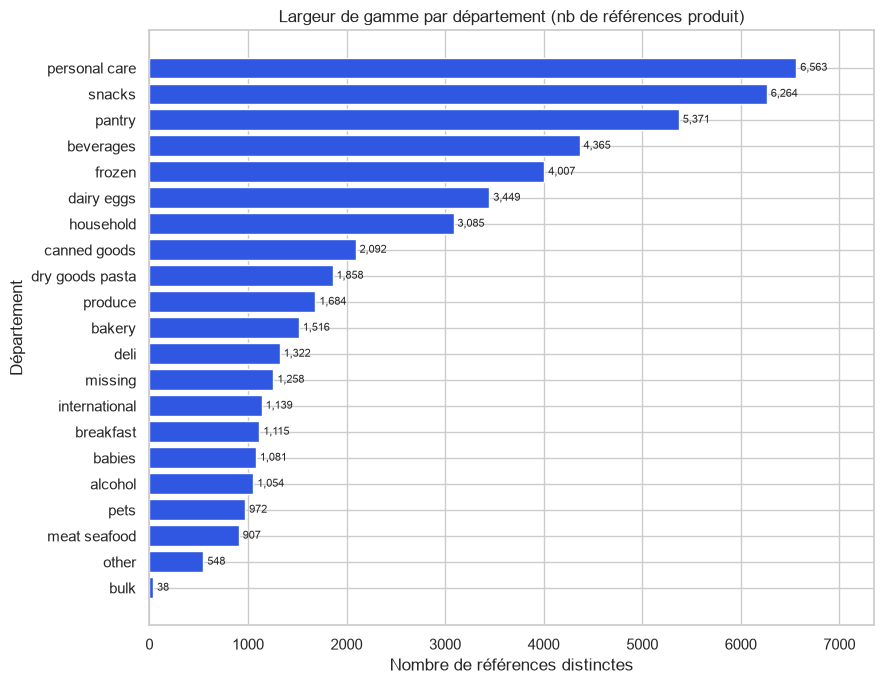

In [14]:
refs_per_dept = (
    products_full.groupby("department")["product_id"]
    .nunique()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(refs_per_dept.index, refs_per_dept.values, color="#3057E1")
ax.set_xlabel("Nombre de références distinctes")
ax.set_ylabel("Département")
ax.set_title("Largeur de gamme par département (nb de références produit)")
for bar, val in zip(bars, refs_per_dept.values):
    ax.text(val + 40, bar.get_y() + bar.get_height()/2, f"{val:,}",
            va="center", fontsize=8)
ax.set_xlim(0, refs_per_dept.max()*1.12)
plt.tight_layout()
plt.show()


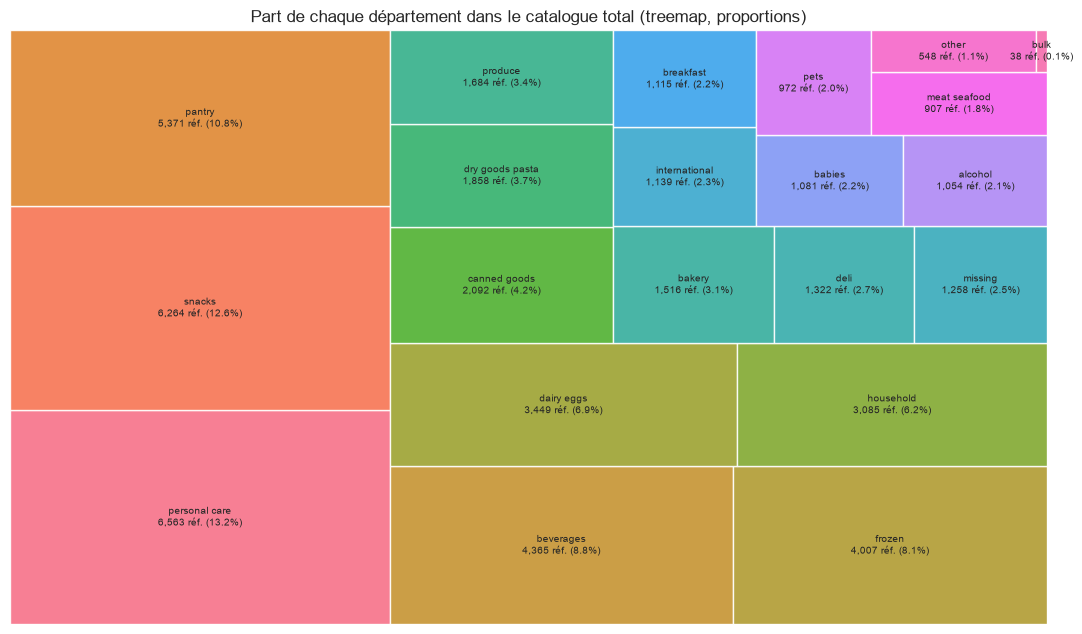

In [15]:
refs_per_dept_desc = refs_per_dept.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 6.5))
colors = sns.color_palette("husl", len(refs_per_dept_desc))
squarify.plot(
    sizes=refs_per_dept_desc.values,
    label=[f"{d}\n{v:,} réf. ({100*v/refs_per_dept_desc.sum():.1f}%)"
           for d, v in refs_per_dept_desc.items()],
    color=colors, alpha=0.9, ax=ax, text_kwargs={"fontsize": 7.5}
)
ax.set_title("Part de chaque département dans le catalogue total (treemap, proportions)")
ax.axis("off")
plt.tight_layout()
plt.show()


In [16]:
refs_per_aisle = (
    products_full.groupby(["department", "aisle"])["product_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 5 rayons les mieux fournis :")
print(refs_per_aisle.head(5).to_string())
print("\nTop 5 rayons les moins fournis :")
print(refs_per_aisle.tail(5).to_string())


Top 5 rayons les mieux fournis :
department     aisle               
missing        missing                 1258
snacks         candy chocolate         1246
frozen         ice cream ice           1091
personal care  vitamins supplements    1038
dairy eggs     yogurt                  1026

Top 5 rayons les moins fournis :
department  aisle                       
frozen      frozen juice                    47
babies      baby accessories                44
produce     packaged produce                32
bulk        bulk grains rice dried goods    26
            bulk dried fruits vegetables    12


**Lecture :** `personal care` (6 563 réf.) et `snacks` (6 264 réf.) sont, à eux deux, plus larges que les 8 départements les plus étroits réunis. À l'inverse, `bulk` (38 réf.) et `pets` (972 réf.) ont une gamme très restreinte. Cette hétérogénéité n'est pas anormale en soi (elle reflète la diversité naturelle des catégories), mais elle prend tout son sens une fois comparée à la demande réelle - objet de la question suivante.

## Question 2 - L'offre est-elle alignée sur la demande ?

**Objectif :** comparer, pour chaque département, sa part dans le catalogue (nombre de références) à sa part dans le volume réellement vendu (nombre de lignes de commande). Un département avec beaucoup de références mais peu de ventes est potentiellement **sur-assorti** ; l'inverse suggère un **sous-assortiment** relatif.

**Graphique choisi :** nuage de points (scatter) - c'est le graphique adapté pour représenter une **relation** entre deux variables continues (ici : part de l'offre vs part de la demande), avec une droite de référence y = x pour visualiser l'écart à l'alignement parfait.

In [17]:
demand_per_dept = op_full.groupby("department").size()

q2 = pd.DataFrame({
    "nb_refs": refs_per_dept_desc,
    "volume_sold": demand_per_dept
}).fillna(0)

q2["share_refs_pct"]   = 100 * q2["nb_refs"]   / q2["nb_refs"].sum()
q2["share_volume_pct"] = 100 * q2["volume_sold"] / q2["volume_sold"].sum()
q2["ratio_demande_sur_offre"] = q2["share_volume_pct"] / q2["share_refs_pct"]

corr = q2[["nb_refs", "volume_sold"]].corr().iloc[0, 1]
print(f"Corrélation (nb références, volume vendu) au niveau département : {corr:.2f}")


Corrélation (nb références, volume vendu) au niveau département : 0.25


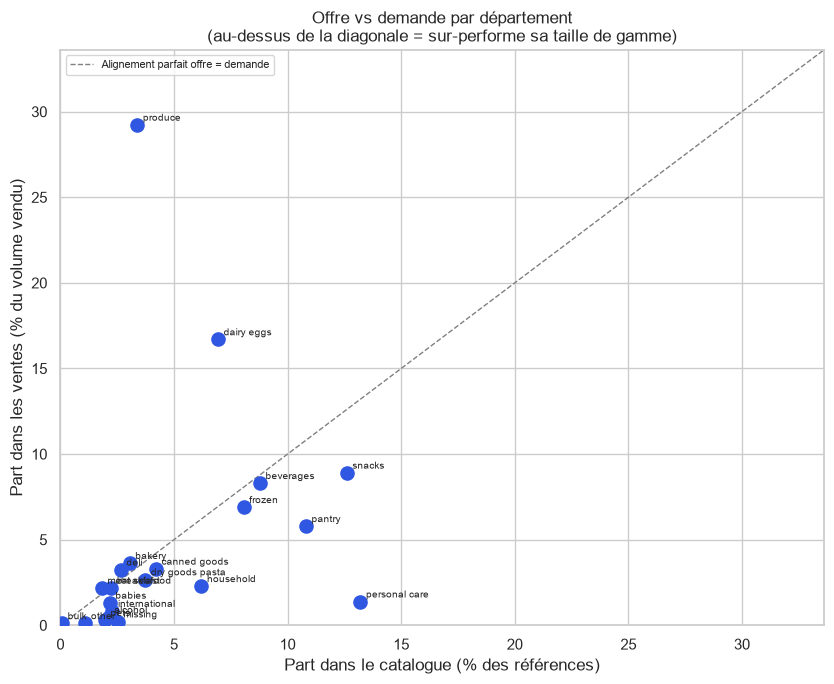

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.scatter(q2["share_refs_pct"], q2["share_volume_pct"],
           s=90, color="#3057E1", zorder=3)

max_val = max(q2["share_refs_pct"].max(), q2["share_volume_pct"].max()) * 1.15
ax.plot([0, max_val], [0, max_val], linestyle="--", color="grey",
        linewidth=1, label="Alignement parfait offre = demande")

for dept, row in q2.iterrows():
    ax.annotate(dept, (row["share_refs_pct"], row["share_volume_pct"]),
                fontsize=7.5, xytext=(4, 3), textcoords="offset points")

ax.set_xlabel("Part dans le catalogue (% des références)")
ax.set_ylabel("Part dans les ventes (% du volume vendu)")
ax.set_title("Offre vs demande par département\n(au-dessus de la diagonale = sur-performe sa taille de gamme)")
ax.legend(loc="upper left", fontsize=8)
ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
plt.tight_layout()
plt.show()


In [19]:
print("Départements où la demande dépasse le plus l'offre relative (ratio demande/offre) :")
print(q2.sort_values("ratio_demande_sur_offre", ascending=False)[
    ["nb_refs", "volume_sold", "share_refs_pct", "share_volume_pct", "ratio_demande_sur_offre"]
].round(2).head(5).to_string())

print("\nDépartements les plus sur-assortis par rapport à leur demande :")
print(q2.sort_values("ratio_demande_sur_offre")[
    ["nb_refs", "volume_sold", "share_refs_pct", "share_volume_pct", "ratio_demande_sur_offre"]
].round(2).head(5).to_string())


Départements où la demande dépasse le plus l'offre relative (ratio demande/offre) :
              nb_refs  volume_sold  share_refs_pct  share_volume_pct  ratio_demande_sur_offre
department                                                                                   
produce          1684      9479291            3.39             29.23                     8.62
dairy eggs       3449      5414016            6.94             16.69                     2.40
bulk               38        34573            0.08              0.11                     1.39
deli             1322      1051249            2.66              3.24                     1.22
meat seafood      907       708931            1.83              2.19                     1.20

Départements les plus sur-assortis par rapport à leur demande :
               nb_refs  volume_sold  share_refs_pct  share_volume_pct  ratio_demande_sur_offre
department                                                                                    
mis

**Lecture :** la corrélation entre largeur de gamme et volume vendu est **faible (≈ 0.25)** au niveau département - le nombre de références n'est pas un bon prédicteur des ventes. Deux cas extrêmes :
- **`produce`** (fruits & légumes) : seulement 5.2 % des références du catalogue, mais **29 %** du volume vendu total → ratio demande/offre ≈ **8.6**. Un rayon très étroit qui écrase tout le reste en performance.
- **`personal care`** : 20 % des références (le plus gros département en nombre de refs) pour seulement **1.4 %** du volume vendu → ratio ≈ **0.10**. Gamme largement sur-dimensionnée par rapport à la demande réelle.

**Piste d'action :** resserrer l'assortiment `personal care` (et dans une moindre mesure `snacks`, `pantry`) au profit d'un renforcement de `produce`, qui tourne visiblement bien au-delà de sa taille de gamme.

## Question 3 - Rotation de l'assortiment : quelle concentration des ventes ?

**Objectif :** vérifier si une minorité de produits porte l'essentiel des ventes (logique Pareto / loi de puissance), et quantifier la longue traîne de produits à faible rotation.

**Graphique choisi :** courbe de Lorenz (cumul des ventes triées par produit, en fonction du cumul de produits) - adapté pour représenter une **distribution/concentration**, différent des barres et du scatter déjà utilisés.

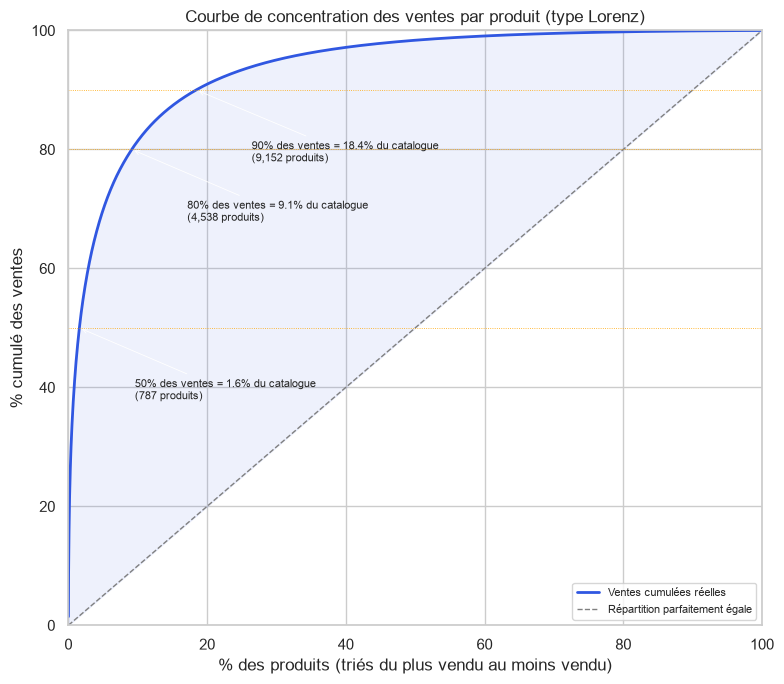

In [20]:
sales_per_product = order_products.groupby("product_id").size().sort_values(ascending=False)
total_units = sales_per_product.sum()
n_products = len(sales_per_product)

cum_products_pct = np.arange(1, n_products + 1) / n_products * 100
cum_sales_pct = sales_per_product.cumsum().values / total_units * 100

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(cum_products_pct, cum_sales_pct, color="#3057E1", linewidth=2,
        label="Ventes cumulées réelles")
ax.plot([0, 100], [0, 100], linestyle="--", color="grey", linewidth=1,
        label="Répartition parfaitement égale")
ax.fill_between(cum_products_pct, cum_sales_pct, cum_products_pct,
                 color="#3057E1", alpha=0.08)

for target in [50, 80, 90]:
    n_needed = (sales_per_product.cumsum() / total_units <= target/100).sum() + 1
    pct_catalog = 100 * n_needed / n_products
    ax.axhline(target, color="orange", linewidth=0.6, linestyle=":")
    ax.annotate(f"{target}% des ventes = {pct_catalog:.1f}% du catalogue\n({n_needed:,} produits)",
                xy=(pct_catalog, target), xytext=(pct_catalog + 8, target - 12),
                fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.6))

ax.set_xlabel("% des produits (triés du plus vendu au moins vendu)")
ax.set_ylabel("% cumulé des ventes")
ax.set_title("Courbe de concentration des ventes par produit (type Lorenz)")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()


In [21]:
low_rotation = sales_per_product[sales_per_product <= 5]
print(f"Produits vendus au plus 5 fois sur toute la période : {len(low_rotation):,} "
      f"({100*len(low_rotation)/n_products:.1f}% du catalogue vendu)")
print(f"Leur poids dans le volume total vendu : {100*low_rotation.sum()/total_units:.3f}%")


Produits vendus au plus 5 fois sur toute la période : 3,171 (6.4% du catalogue vendu)
Leur poids dans le volume total vendu : 0.037%


**Lecture :** la concentration est extrême - **1.6 % des produits (787 réf.) génèrent 50 % des ventes**, et **9.1 % du catalogue génère 80 % des ventes**. À l'autre bout, **6.4 % des produits vendus** (3 171 références) ne représentent que **0.04 %** du volume total - une très longue traîne de produits presque jamais achetés.

**Piste d'action :** ces ~3 000 références à très faible rotation sont des candidates naturelles à un audit de déréférencement (sous réserve qu'elles ne servent pas un objectif de gamme stratégique, ex. produits de niche à forte marge ou d'image).

## Question 4 - Quels rayons sont le plus souvent achetés ensemble ?

**Objectif :** identifier des paires de rayons dont la co-présence dans une même commande dépasse ce que le hasard prédirait (indépendance des deux rayons), afin de proposer des rapprochements en magasin ou des mises en avant croisées.

**Métrique :** le **lift** - rapport entre la probabilité observée que deux rayons soient achetés ensemble et la probabilité qu'on obtiendrait s'ils étaient indépendants. `lift = 1` → indépendance, `lift > 1` → association positive.

**Graphique choisi :** heatmap (matrice) - seul format adapté pour visualiser une relation many-to-many entre catégories, distinct des barres/scatter/courbe déjà utilisés. Analyse menée aux deux niveaux demandés : département (vue d'ensemble) et rayon (plus fin).

In [22]:
def build_cooccurrence(df, col, id_range):
    """Construit la matrice de co-occurrence (nb commandes contenant à la fois cat i et cat j)
    et le lift associé, à partir d'un DataFrame contenant order_id et la colonne catégorielle."""
    pairs = df[["order_id", col]].drop_duplicates()
    order_codes, order_uniques = pd.factorize(pairs["order_id"])
    cat_codes = pairs[col].values - 1
    n_cat = len(id_range)

    mat = sparse.csr_matrix(
        (np.ones(len(pairs), dtype=np.int32), (order_codes, cat_codes)),
        shape=(len(order_uniques), n_cat)
    )
    co_matrix = (mat.T @ mat).toarray()
    support = mat.sum(axis=0).A1
    n_orders = len(order_uniques)

    lift = np.zeros_like(co_matrix, dtype=float)
    for i in range(n_cat):
        for j in range(n_cat):
            if i != j and support[i] > 0 and support[j] > 0:
                p_ij = co_matrix[i, j] / n_orders
                p_i, p_j = support[i] / n_orders, support[j] / n_orders
                lift[i, j] = p_ij / (p_i * p_j)
    return co_matrix, lift, support, n_orders

op_dept = op_full.merge(products_full[["product_id","department_id"]], on="product_id", how="left") \
    if "department_id" not in op_full.columns else op_full


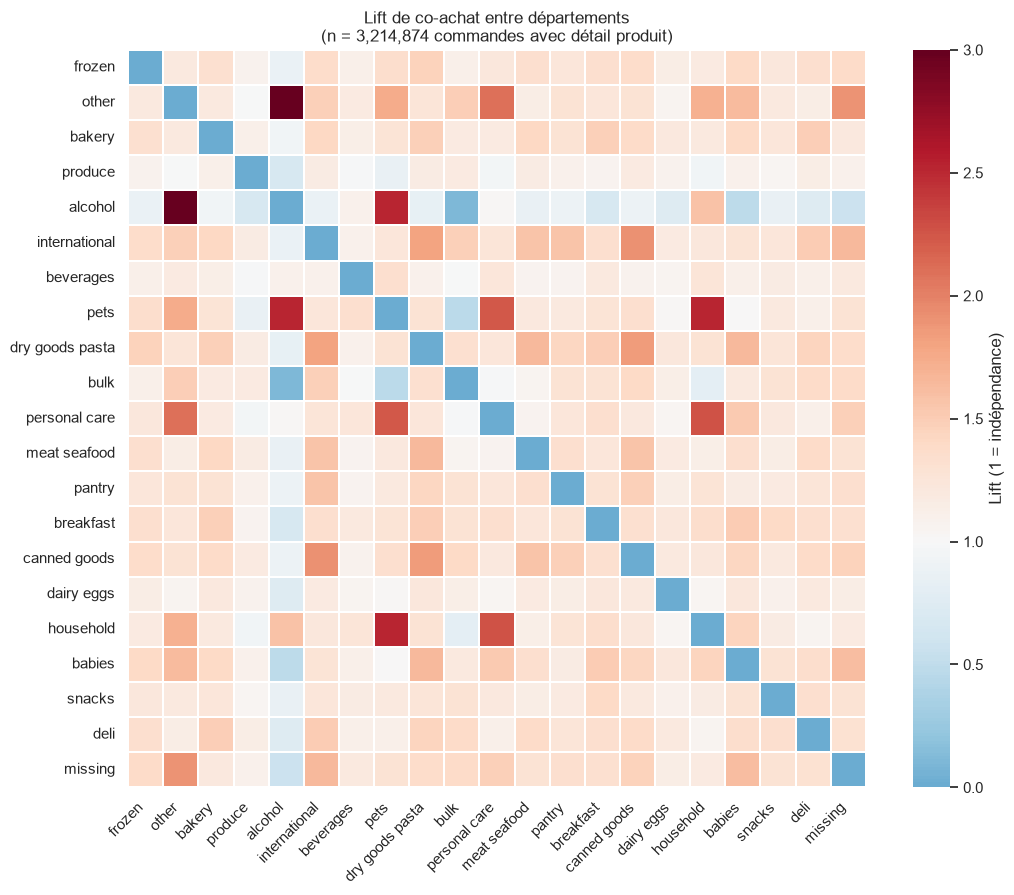

In [23]:
# --- Niveau département (21 catégories) ---
op_dept_ids = order_products.merge(products_full[["product_id","department_id"]], on="product_id")
co_dept, lift_dept, sup_dept, n_orders_detail = build_cooccurrence(
    op_dept_ids, "department_id", range(1, 22)
)
dept_names = departments.set_index("department_id")["department"].reindex(range(1, 22)).values

lift_dept_df = pd.DataFrame(lift_dept, index=dept_names, columns=dept_names)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(lift_dept_df, cmap="RdBu_r", center=1, vmin=0, vmax=3,
            square=True, linewidths=0.3, cbar_kws={"label": "Lift (1 = indépendance)"},
            ax=ax)
ax.set_title(f"Lift de co-achat entre départements\n(n = {n_orders_detail:,} commandes avec détail produit)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


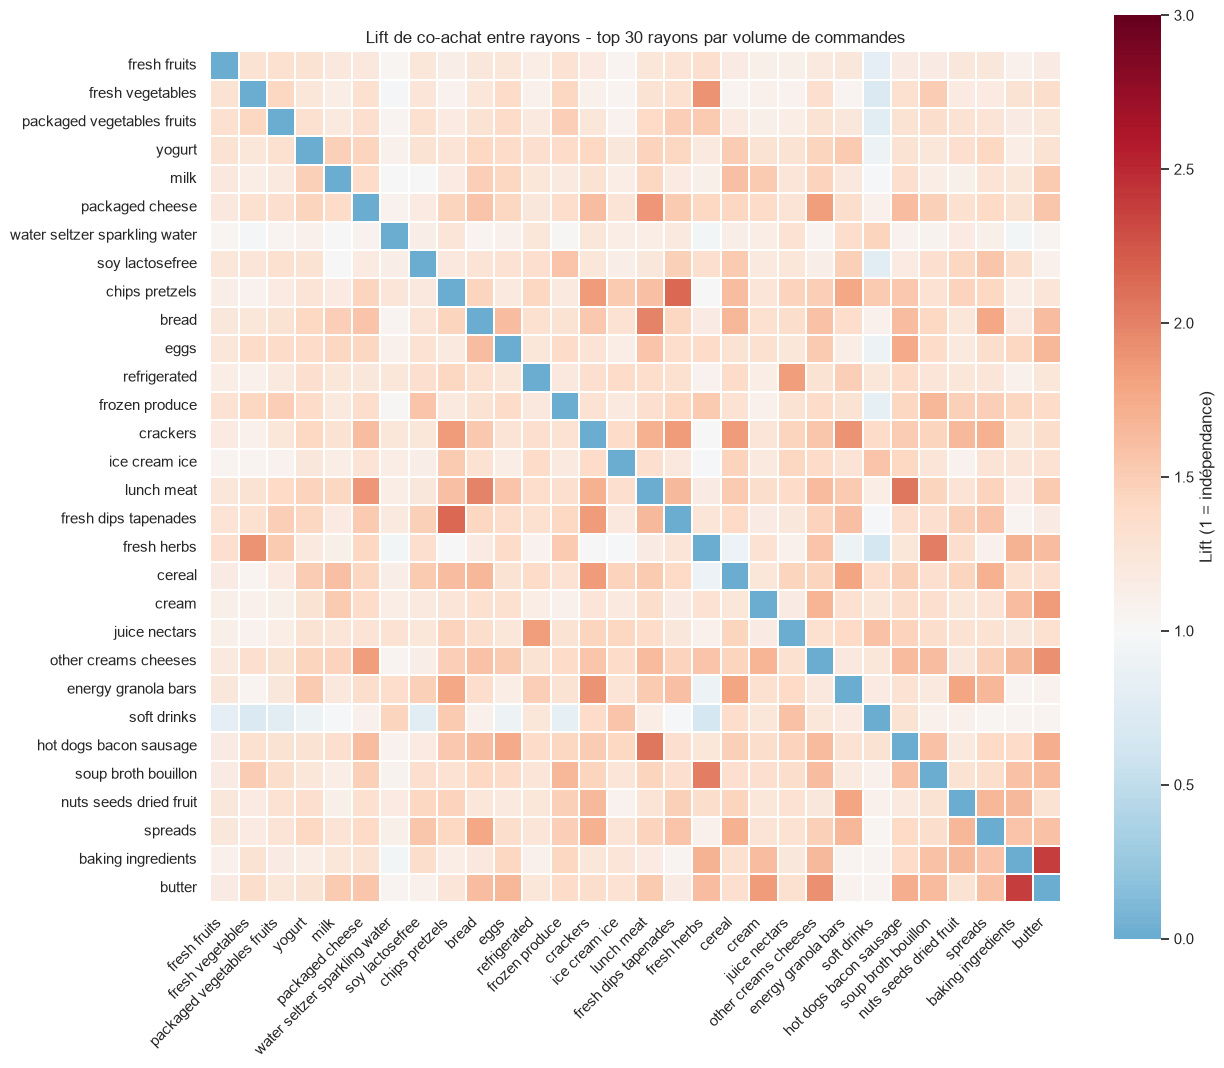

In [24]:
# --- Niveau rayon (134 catégories) - on garde les rayons ayant un minimum de volume
# pour la lisibilité de la heatmap (rayons anecdotiques exclus de l'affichage, pas du calcul)
op_aisle_ids = order_products.merge(products_full[["product_id","aisle_id"]], on="product_id")
co_aisle, lift_aisle, sup_aisle, _ = build_cooccurrence(op_aisle_ids, "aisle_id", range(1, 135))
aisle_names_all = aisles.set_index("aisle_id")["aisle"].reindex(range(1, 135)).values

# top 30 rayons par volume de commandes, pour une heatmap lisible
top30_idx = np.argsort(sup_aisle)[::-1][:30]
lift_top30 = lift_aisle[np.ix_(top30_idx, top30_idx)]
names_top30 = aisle_names_all[top30_idx]

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(pd.DataFrame(lift_top30, index=names_top30, columns=names_top30),
            cmap="RdBu_r", center=1, vmin=0, vmax=3, square=True, linewidths=0.2,
            cbar_kws={"label": "Lift (1 = indépendance)"}, ax=ax)
ax.set_title("Lift de co-achat entre rayons - top 30 rayons par volume de commandes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [25]:
def lift_report(name_a_substr, name_b_substr):
    ia = [i for i, n in enumerate(aisle_names_all) if name_a_substr in n][0]
    ib = [i for i, n in enumerate(aisle_names_all) if name_b_substr in n][0]
    print(f"{aisle_names_all[ia]:<25} <-> {aisle_names_all[ib]:<25} "
          f"lift={lift_aisle[ia, ib]:5.2f}   co_achats={co_aisle[ia, ib]:>7,}   "
          f"support_a={sup_aisle[ia]:>7,}   support_b={sup_aisle[ib]:>7,}")

print("Vérification des hypothèses classiques du sujet :\n")
lift_report("specialty cheeses", "red wines")
lift_report("packaged cheese", "red wines")
lift_report("other creams cheeses", "red wines")
lift_report("dog food", "cat food")


Vérification des hypothèses classiques du sujet :

specialty cheeses         <-> red wines                 lift= 1.16   co_achats=    702   support_a= 77,171   support_b= 25,306
packaged cheese           <-> red wines                 lift= 0.91   co_achats=  5,267   support_a=737,899   support_b= 25,306
other creams cheeses      <-> red wines                 lift= 1.12   co_achats=  2,456   support_a=278,180   support_b= 25,306
dog food care             <-> cat food care             lift= 4.89   co_achats=  1,371   support_a= 25,965   support_b= 34,688


**Lecture :**

- **Fromage / vin - hypothèse infirmée.** Le lift entre les rayons fromage (`specialty cheeses`, `packaged cheese`, `other creams cheeses`) et vin (`red wines`) tourne autour de **1.0-1.2**, c'est-à-dire proche de l'indépendance statistique. L'association "fromage + vin" existe dans l'imaginaire commercial, mais **n'est pas confirmée par les données** de ce dataset - attention à ne pas construire une action merchandising sur une intuition non vérifiée.
- **Chat / chien - hypothèse confirmée, et plus forte qu'attendu.** `dog food care` et `cat food care` ont un lift de **≈ 4.9** : très largement au-dessus de l'indépendance. Logique une fois qu'on y pense (foyers multi-animaux), mais l'ampleur est notable.
- **Les associations les plus fortes du dataset** concernent en réalité les **rayons alcool entre eux** (vins rouges/blancs/spéciaux, spiritueux, bières - lift jusqu'à ~39) et les **rayons soins/hygiène** (rasage/soin visage, couches/soin bébé) : des paniers "toilette" ou "cave" cohérents, plus nets que le cross-sell alimentaire classique.

**Piste d'action :** rapprocher `dog food care` et `cat food care` en rayon, envisager une mise en avant croisée alcool (vins/spiritueux/bières) plutôt que fromage/vin, et ne pas généraliser une hypothèse de merchandising sans la valider sur les données comme ici.

## Synthèse - Actions proposées (Stock / assortiment)

| # | Constat | Action proposée |
|---|---|---|
| 1 | `personal care` (6 563 réf., 20% du catalogue) ne pèse que 1.4% des ventes ; `produce` (5% du catalogue) pèse 29% des ventes | Resserrer la gamme `personal care` / `snacks` / `pantry`, réinvestir l'espace linéaire vers `produce` |
| 2 | 6.4% du catalogue vendu (~3 171 réf.) ne représente que 0.04% du volume | Auditer ces références à très faible rotation pour déréférencement, sauf exceptions stratégiques |
| 3 | Lift fromage/vin proche de 1 (hypothèse classique non confirmée) | Ne pas investir en rapprochement fromage/vin sans re-test A/B en magasin |
| 4 | Lift chat/chien ≈ 4.9, alcool entre eux jusqu'à ~39 | Rapprocher les rayons animaux, regrouper davantage l'offre alcool (vin/spiritueux/bière) |


---
# Analyse des performances du e-commerce

## *Question 1 : Quels sont les produits les plus vendus ?*

**Type de question :** on veut **classer** des catégories (les produits) du plus vendu au moins vendu. Selon les règles de visualisation, il s'agit d'une une **comparaison**, donc on utilise un graphique en **barres**. Comme les noms de produits sont longs et nombreux, on prend le **top 15** en **barres horizontales**.

« Le plus vendu » = le produit qui apparaît dans le plus grand nombre de lignes de `order_products`.

Sachant qu'une une ligne de `order_products` = un produit acheté dans une commande, on compte les lignes par `product_id`.

In [26]:

ventes_par_produit = order_products.groupby("product_id").size()
ventes_par_produit.head()

product_id
1    1852
2      90
3     277
4     329
5      15
dtype: int64

`.size()` renvoie une **Series** : index = `product_id`, valeur = nombre de ventes.
On veut les plus gros :

- `.sort_values(ascending=False)` : de la plus grande valeur à la plus petite
- `.head(15)` : on garde les 15 premières


In [27]:
top15 = ventes_par_produit.sort_values(ascending=False).head(15)
top15


product_id
24852    472565
13176    379450
21137    264683
21903    241921
47209    213584
47766    176815
47626    152657
16797    142951
26209    140627
27845    137905
27966    137057
22935    113426
24964    109778
45007    104823
39275    100060
dtype: int64

On a des `product_id` (des numéros), pas des noms. Deux étapes :

- `.reset_index(name="ventes")` : transforme la Series en **tableau** à 2 colonnes
  (`product_id`, `ventes`).
- `.merge(products[["product_id", "product_name"]], on="product_id")` : rapproche
  de `products` pour récupérer `product_name` à partir du `product_id`.

In [28]:
top15_noms = (
    top15
    .reset_index(name="ventes")                         
    .merge(products[["product_id", "product_name"]], on="product_id")
)
top15_noms


,product_id,ventes,product_name
0,24852,472565,Banana
1,13176,379450,Bag of Organic Bananas
2,21137,264683,Organic Strawberries
3,21903,241921,Organic Baby Spinach
4,47209,213584,Organic Hass Avocado
5,47766,176815,Organic Avocado
6,47626,152657,Large Lemon
7,16797,142951,Strawberries
8,26209,140627,Limes
9,27845,137905,Organic Whole Milk


**Le graphique.** `plt.barh(noms, valeurs)` = barres **horizontales** (pratique
quand les libellés sont longs). Pour que le produit n°1 apparaisse tout en haut, on trie le tableau en ordre **croissant**.


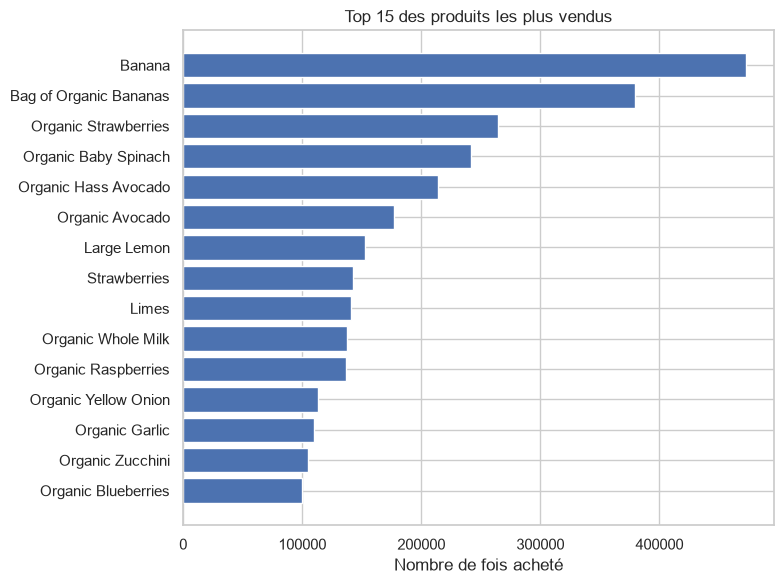

In [29]:
graph = top15_noms.sort_values("ventes") 

plt.figure(figsize=(8, 6))
plt.barh(graph["product_name"], graph["ventes"])
plt.xlabel("Nombre de fois acheté")
plt.title("Top 15 des produits les plus vendus")
plt.tight_layout()
plt.show()


**Observations :**

- Le classement est dominé par des **fruits et légumes frais**, très souvent bio :
  bananes, fraises, épinards, avocats, myrtilles... (mention *Organic* récurrente).
- Le produit n°1 (*Banana*) pèse à lui seul ~1,46 % de toutes les lignes vendues du site
- Ce sont des produits **peu chers achetés très fréquemment** (la fréquence d'achat)

**Piste business :**

Veiller au réapprovisionnement ininterrompu de ces 15 produits et les mettre en tête de parcours ou dans les suggestions par défaut pour accélérer le remplissage du panier.

## *Question 2 : Quel est le ratio de commandes bio vs non-bio ?*

**Type de question :** on veut une **part d'un tout** (les commandes qui contiennent
du bio, rapportées à l'ensemble des commandes). D'après les règles de visualisation,
une proportion se montre avec une **barre empilée à 100 %**.

**« Commande bio »** = une commande qui contient **au moins un** produit bio. Le
seul indice pour repérer un produit bio est son **nom** : on considère bio tout
produit dont le `product_name` contient « organic ». C'est une approximation (un
produit bio mal nommé passera pour non-bio), mais c'est la seule information
disponible.


In [30]:
produits["bio"] = produits["product_name"].str.contains("organic", case=False, na=False)

nb_bio = produits["bio"].sum()
print(f"Produits bio : {nb_bio:,} / {len(produits):,} ({nb_bio / len(produits):.1%} du catalogue)")
produits.loc[produits["bio"], ["product_name", "aisle", "department"]].head()


Produits bio : 5,036 / 49,688 (10.1% du catalogue)


,product_name,aisle,department
22,Organic Turkey Burgers,packaged poultry,meat seafood
32,Organic Spaghetti Style Pasta,dry pasta,dry goods pasta
40,Organic Sourdough Einkorn Crackers Rosemary,crackers,snacks
42,Organic Clementines,packaged vegetables fruits,produce
46,Onion Flavor Organic Roasted Seaweed Snack,asian foods,international


`str.contains("organic", case=False)` teste, pour chaque nom de produit, la présence
du mot « organic » sans tenir compte de la casse ; `na=False` traite un nom manquant
comme « pas bio ».

Environ **10 % du catalogue** est bio. On reporte maintenant cette étiquette sur
chaque ligne de `order_products` (une ligne = un produit dans une commande). Plutôt
qu'un `merge` sur 32 M de lignes, on construit l'ensemble des `product_id` bio et on
teste l'appartenance avec `.isin()`.


In [31]:
bio_ids = set(produits.loc[produits["bio"], "product_id"])
order_products["bio"] = order_products["product_id"].isin(bio_ids)

part_lignes_bio = order_products["bio"].mean()
print(f"Lignes produits bio : {part_lignes_bio:.1%}")

Lignes produits bio : 31.6%


**31,6 %** des lignes achetées sont des produits bio : trois fois plus que la part
du bio dans le catalogue (10 %). Les produits bio se vendent donc proportionnellement
bien mieux que les autres.

On passe au niveau **commande**. Une commande est « bio » si **au moins un** de ses
produits l'est. `groupby("order_id")["bio"].agg(["any", "all"])` calcule en un seul
passage, pour chaque commande : `any` = contient-elle au moins un produit bio,
`all` = sont-ils **tous** bio.


In [32]:
agg = order_products.groupby("order_id")["bio"].agg(["any", "all"])

part_commandes_bio     = agg["any"].mean()
part_commandes_100_bio = agg["all"].mean()
print(f"Commandes avec au moins un produit bio : {part_commandes_bio:.1%}")
print(f"Commandes sans aucun produit bio       : {1 - part_commandes_bio:.1%}")
print(f"Commandes 100 % bio                    : {part_commandes_100_bio:.1%}")

Commandes avec au moins un produit bio : 73.6%
Commandes sans aucun produit bio       : 26.4%
Commandes 100 % bio                    : 2.5%


**73,6 % des commandes** contiennent au moins un produit bio, contre 26,4 % sans
aucun. Le bio n'est pas un segment de niche sur ce site : la majorité des paniers
sont concernés.

On visualise les deux niveaux de lecture (commande / ligne produit) l'un sous
l'autre, chacun en barre empilée à 100 %.


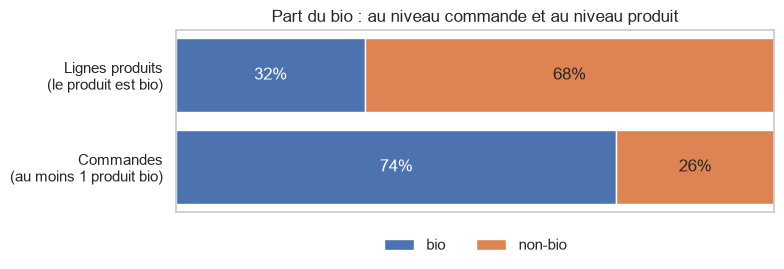

In [33]:
niveaux      = ["Commandes\n(au moins 1 produit bio)", "Lignes produits\n(le produit est bio)"]
part_bio     = [part_commandes_bio, part_lignes_bio]
part_non_bio = [1 - p for p in part_bio]

plt.figure(figsize=(8, 3))
plt.barh(niveaux, part_bio, label="bio")
plt.barh(niveaux, part_non_bio, left=part_bio, label="non-bio")

for i, p in enumerate(part_bio):
    plt.text(p / 2,           i, f"{p:.0%}",     va="center", ha="center", color="white")
    plt.text(p + (1 - p) / 2, i, f"{1 - p:.0%}", va="center", ha="center")

plt.xlim(0, 1)
plt.xticks([])
plt.title("Part du bio : au niveau commande et au niveau produit")
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**Observations :**

- **73,6 % des commandes** contiennent du bio, mais seulement **31,6 % des lignes
  produits** le sont : dans une commande « bio » typique, le bio cohabite avec une
  majorité de produits non-bio.
- Le bio est **sur-représenté dans les ventes** par rapport à l'offre : 10 % du
  catalogue, 32 % des achats. Ce sont surtout les gros volumes du top 15 (bananes,
  épinards, fraises… en version bio) qui tirent ce chiffre.
- Les commandes **100 % bio** sont rares (~2,5 %) : le bio est un complément de
  panier.

**Piste business :**

Le bio est un réflexe d'achat de masse, pas une niche. Sur les 26 % de commandes
sans aucun produit bio, proposer l'équivalent bio d'un produit déjà au panier au
moment de l'ajout pour convertir ces paniers.


## *Question 3 : Quel est le taux de réachat, au global et par département ?*

**Mesure.** La colonne `reordered` vaut 1 si le client avait déjà commandé ce
produit auparavant, 0 sinon. Le taux de réachat d'un ensemble de lignes est la
moyenne de `reordered` sur ces lignes.

**Visualisation.** On compare des catégories (les départements) sur un même
indicateur : c'est une comparaison, donc un diagramme en barres. Le taux global sert
de repère.


In [34]:
print(f"Taux de reachat global : {order_products['reordered'].mean():.1%}")


Taux de reachat global : 59.0%


59 % des produits achetés avaient déjà été commandés par le client. On décompose par
département : on rattache chaque ligne à son `department_id` via `produits`, puis on
calcule la moyenne de `reordered` par département. On garde aussi le nombre de lignes
pour situer le poids de chaque département.


In [35]:
dept_par_produit = produits.set_index("product_id")["department_id"]
order_products["department_id"] = order_products["product_id"].map(dept_par_produit).astype("int16")

reachat_dept = (
    order_products.groupby("department_id")["reordered"].agg(taux="mean", lignes="size")
    .join(departments.set_index("department_id")["department"])
    .sort_values("taux")
)
reachat_dept


,taux,lignes,department
department_id,,,
11,0.321129,447123,personal care
13,0.346721,1875577,pantry
6,0.369229,269253,international
21,0.395849,69145,missing
17,0.402178,738666,household
2,0.407980,36291,other
15,0.457405,1068058,canned goods
9,0.461076,866627,dry goods pasta
1,0.541885,2236432,frozen


On trace les départements du taux le plus faible au plus fort, avec une ligne
verticale au taux global.


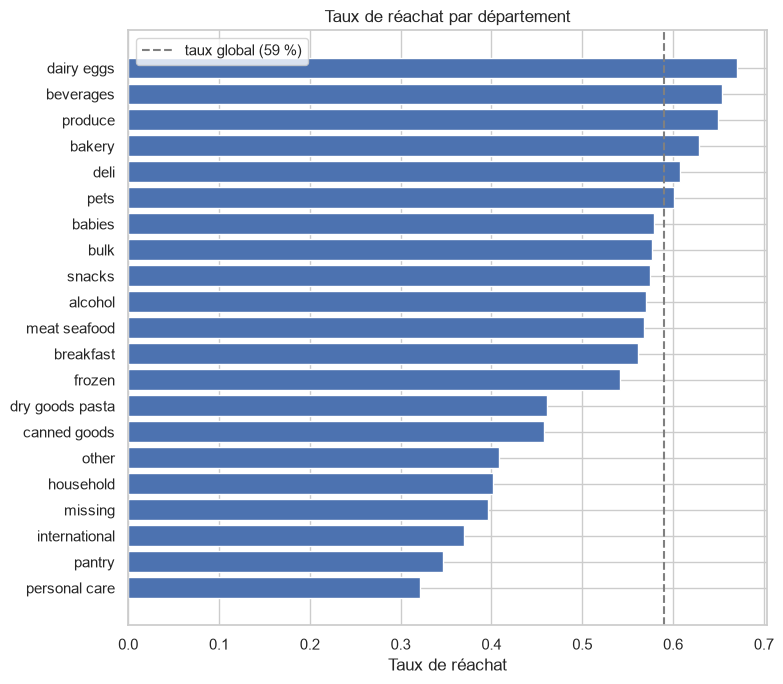

In [36]:
plt.figure(figsize=(8, 7))
plt.barh(reachat_dept["department"], reachat_dept["taux"])
plt.axvline(order_products["reordered"].mean(), color="grey", linestyle="--",
            label="taux global (59 %)")
plt.xlabel("Taux de réachat")
plt.title("Taux de réachat par département")
plt.legend()
plt.tight_layout()
plt.show()


**Observations :**

- Le taux de réachat va de **32 % (personal care)** à **67 % (dairy eggs)**.
- Au-dessus de la moyenne : des consommables du quotidien (dairy eggs, beverages,
  produce, bakery, deli), qui s'épuisent vite et se rachètent.
- En dessous : des achats ponctuels ou de stock (personal care, pantry, household,
  international, canned goods).
- Les deux plus gros départements en volume (produce 9,5 M lignes, dairy eggs
  5,4 M) sont aussi parmi les plus fidélisants : le cœur du chiffre d'affaires est
  récurrent.

**Piste business :**

Cibler les départements à fort volume mais faible réachat (pantry, canned goods,
frozen) avec des rappels de réassort ou des abonnements : produits que le client
rachètera mais oublie. Sur les départements à fort réachat, la priorité est la
disponibilité, pas la promotion.


## *Question 4 : Quelle est la concentration des ventes ?*

Cette question est traitée en détail dans la partie *Stock / assortiment*, section **"Question 3 - Rotation de l'assortiment"** (courbe de concentration, seuils 50/80/90 %, et poids de la longue traîne à faible rotation). Nous avons le même résultat (9,1 % du catalogue = 80 % des ventes).
